# **Clasificación de la afectación de incendios forestales en turberas de Tierra del Fuego mediante indicadores fisicoquímicos del suelo**

**Dataset:** Muestras_FyQ_procesado.csv

**Origen del dataset:** proviene del notebook de preprocesamiento.

**Objetivo:** Desarrollar y evaluar modelos de Aprendizaje Automático que clasifiquen la severidad del fuego (Low / Moderate / High) en turberas de Sphagnum de Tierra del Fuego a partir de propiedades fisicoquímicas del suelo, comparando Regresión Logística Multinomial y KNN bajo validación agrupada por turbera, e identificar un subconjunto reducido de variables predictoras que preserve la capacidad de discriminación.

**Notebook:** flujo completo de modelado. Iniciamos con la preparación, limpiando y transformando los datos para dividirlos en entrenamiento y prueba. Luego, avanzamos al entrenamiento y evaluación, donde ajustamos el algoritmo y validamos su rendimiento mediante métricas clave. A continuación, analizamos la importancia de las variables para identificar qué factores tienen mayor impacto en las predicciones. Finalmente, realizamos una comparación de escenarios para contrastar distintas configuraciones o supuestos, permitiéndonos seleccionar la solución más robusta para tomar decisiones.

**Variable objetivo:** Burn_Severity

**Alumna:** Sandra Vargas | **Profesor:** Lic. Nicolás Caballero

# **Preparación de datos y validación agrupada**

In [4]:
# ---------------------------
# 0. IMPORTACIONES Y CONFIG
# ---------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import RobustScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, GridSearchCV
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix,
                             classification_report)
from sklearn.inspection import permutation_importance
import sklearn

print("scikit-learn version:", sklearn.__version__)
assert tuple(int(x) for x in sklearn.__version__.split('.')[:2]) >= (1, 0), \
    "Se requiere scikit-learn >= 1.0 para StratifiedGroupKFold"

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

scikit-learn version: 1.6.1


In [5]:
# --------------------------------------
# 1. CARGA Y EXPLORACIÓN DE VERIFICACIÓN
# --------------------------------------
df = pd.read_csv("data/interim/Muestras_FyQ_procesado.csv")

print("=" * 70)
print("1. EXPLORACIÓN DEL ARCHIVO PORCESADO")
print("=" * 70)
print("Dimensiones:", df.shape)
print("\nTipos de datos:\n", df.dtypes)
print("\nValores faltantes por columna:\n", df.isna().sum())
print("\nDistribución de target (0=Low,1=Moderate,2=High):\n",
      df['target'].value_counts().sort_index())
print("\nDistribución de Burn_Severity:\n", df['Burn_Severity'].value_counts())
print("\nTurberas disponibles:\n", df['Turbera'].value_counts())
print("\nVerificación target<->Burn_Severity:")
print(df.groupby('Burn_Severity')['target'].unique())

1. EXPLORACIÓN DEL ARCHIVO PORCESADO
Dimensiones: (231, 15)

Tipos de datos:
 N                    int64
Turbera             object
Transecta           object
ID_SOBRE             int64
Microtopography     object
Burn_Severity       object
pH                 float64
CE                 float64
DOB                float64
MO                 float64
HD                 float64
BD                 float64
VWC                float64
GWC                float64
target               int64
dtype: object

Valores faltantes por columna:
 N                  0
Turbera            0
Transecta          0
ID_SOBRE           0
Microtopography    0
Burn_Severity      0
pH                 0
CE                 0
DOB                0
MO                 0
HD                 0
BD                 0
VWC                0
GWC                0
target             0
dtype: int64

Distribución de target (0=Low,1=Moderate,2=High):
 target
0     71
1     60
2    100
Name: count, dtype: int64

Distribución de Burn_Severity

In [6]:
# ---------------------------
# 2. DEFINICIÓN DE VARIABLES
# ---------------------------
y = df['target'].astype(int).values
grupos = df['Turbera'].values

# Predictores fisicoquímicos disponibles.
# Nota: Ntotal no está en el CSV entregado (el txt indica excluirla por 73.2% NA).
features = ['pH', 'CE', 'DOB', 'MO', 'HD', 'BD', 'VWC']
X = df[features].copy()

print("\nPredictores seleccionados:", features)
print("Dimensiones de X:", X.shape)
print("Valores faltantes en X:", X.isna().sum().sum())
print("\nEstadísticos descriptivos:\n", X.describe().T.round(3))


Predictores seleccionados: ['pH', 'CE', 'DOB', 'MO', 'HD', 'BD', 'VWC']
Dimensiones de X: (231, 7)
Valores faltantes en X: 0

Estadísticos descriptivos:
      count     mean      std     min      25%      50%      75%       max
pH   231.0    3.976    0.158   3.310    3.885    3.980    4.070     4.470
CE   231.0  229.244  252.519  64.700  112.700  160.800  196.650  2760.000
DOB  231.0    0.818    0.756   0.000    0.000    0.800    1.200     3.800
MO   231.0   95.221    2.747  84.938   93.667   96.179   97.305    98.482
HD   231.0    0.134    0.056   0.003    0.098    0.126    0.170     0.346
BD   231.0    0.055    0.024   0.020    0.039    0.047    0.061     0.138
VWC  231.0    0.445    0.134   0.166    0.358    0.430    0.499     0.907


In [7]:
# ---------------------------------------------
# 3. PREPROCESADOR (RobustScaler + log1p en CE)
# ---------------------------------------------
def construir_preprocesador(cols):
    """Construye un ColumnTransformer con log1p+RobustScaler para CE
    y RobustScaler para el resto. Si 'CE' no está, solo RobustScaler."""
    log_cols = [c for c in cols if c == 'CE']
    robust_cols = [c for c in cols if c != 'CE']
    transformers = []
    if log_cols:
        transformers.append(('log_ce', Pipeline([
            ('log', FunctionTransformer(np.log1p, validate=True)),
            ('scaler', RobustScaler())
        ]), log_cols))
    if robust_cols:
        transformers.append(('robust_resto', RobustScaler(), robust_cols))
    return ColumnTransformer(transformers, remainder='drop')

preprocesador = construir_preprocesador(features)
X_check = preprocesador.fit_transform(X)
print("\nForma tras preprocesamiento (verificación):", X_check.shape)
print("Medianas por columna (deben ser ~0):",
      np.round(np.median(X_check, axis=0), 3))


Forma tras preprocesamiento (verificación): (231, 7)
Medianas por columna (deben ser ~0): [0. 0. 0. 0. 0. 0. 0.]


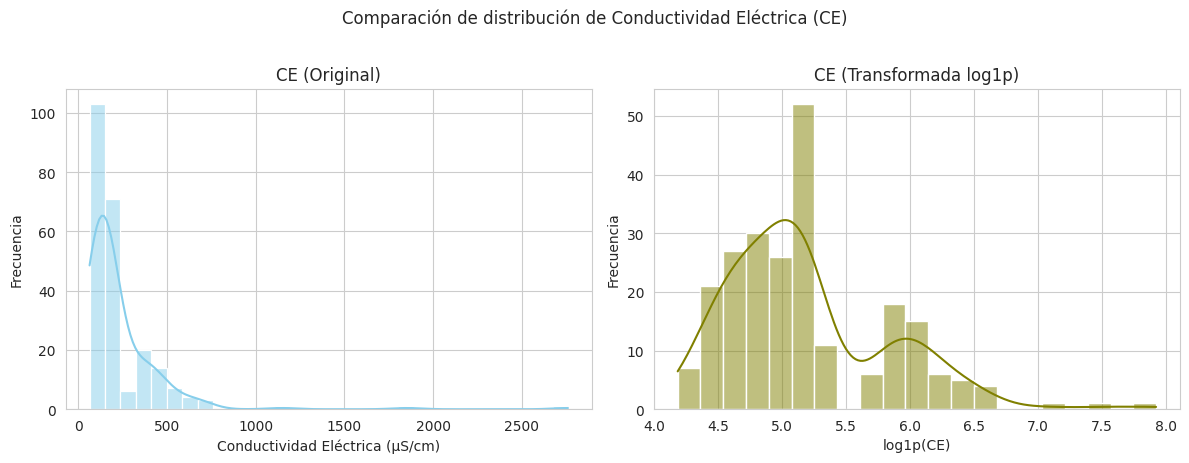

In [20]:
# Histogramas de CE (antes/después de log1p)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df['CE'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('CE (Original)')
axes[0].set_xlabel('Conductividad Eléctrica (µS/cm)')
axes[0].set_ylabel('Frecuencia')

sns.histplot(np.log1p(df['CE']), kde=True, ax=axes[1], color='olive')
axes[1].set_title('CE (Transformada log1p)')
axes[1].set_xlabel('log1p(CE)')
axes[1].set_ylabel('Frecuencia')

plt.suptitle('Comparación de distribución de Conductividad Eléctrica (CE)', y=1.02)
plt.tight_layout()
plt.show()

In [9]:
# ---------------------------
# 4. VALIDACIÓN AGRUPADA: StratifiedGroupKFold vs GroupKFold
# ---------------------------
N_SPLITS = 4
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True,
                            random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=N_SPLITS)

folds_sgkf = list(sgkf.split(X, y, groups=grupos))
folds_gkf  = list(gkf.split(X, y, groups=grupos))

def describir_folds(folds, nombre):
    print(f"\n--- {nombre} ({len(folds)} particiones) ---")
    for i, (tr_idx, te_idx) in enumerate(folds):
        tr_g = sorted(set(grupos[tr_idx]))
        te_g = sorted(set(grupos[te_idx]))
        solap = set(tr_g) & set(te_g)
        dist_te = pd.Series(y[te_idx]).value_counts().sort_index().to_dict()
        # Asegurar que aparezcan las tres claves
        dist_te = {k: dist_te.get(k, 0) for k in [0, 1, 2]}
        print(f"  Fold {i+1}: train={tr_g}  test={te_g}")
        print(f"    solapamiento={solap if solap else 'ninguno ✓'}  "
              f"n_test={len(te_idx)}  clases_test={dist_te}")

print("\n" + "=" * 70)
print("2. VALIDACIÓN AGRUPADA")
print("=" * 70)
describir_folds(folds_sgkf, "StratifiedGroupKFold")
describir_folds(folds_gkf, "GroupKFold (respaldo)")


2. VALIDACIÓN AGRUPADA

--- StratifiedGroupKFold (4 particiones) ---
  Fold 1: train=['B11', 'B21', 'B8', 'B9', 'I2']  test=['B1', 'B3']
    solapamiento=ninguno ✓  n_test=81  clases_test={0: 21, 1: 10, 2: 50}
  Fold 2: train=['B1', 'B11', 'B21', 'B3', 'I2']  test=['B8', 'B9']
    solapamiento=ninguno ✓  n_test=60  clases_test={0: 20, 1: 20, 2: 20}
  Fold 3: train=['B1', 'B21', 'B3', 'B8', 'B9']  test=['B11', 'I2']
    solapamiento=ninguno ✓  n_test=60  clases_test={0: 20, 1: 20, 2: 20}
  Fold 4: train=['B1', 'B11', 'B3', 'B8', 'B9', 'I2']  test=['B21']
    solapamiento=ninguno ✓  n_test=30  clases_test={0: 10, 1: 10, 2: 10}

--- GroupKFold (respaldo) (4 particiones) ---
  Fold 1: train=['B11', 'B21', 'B3', 'B8', 'B9', 'I2']  test=['B1']
    solapamiento=ninguno ✓  n_test=55  clases_test={0: 15, 1: 0, 2: 40}
  Fold 2: train=['B1', 'B11', 'B3', 'B8', 'I2']  test=['B21', 'B9']
    solapamiento=ninguno ✓  n_test=60  clases_test={0: 20, 1: 20, 2: 20}
  Fold 3: train=['B1', 'B21', 'B3', 'B

# **Entrenamiento y evaluación comparativa**

In [10]:
# ---------------------------
# 5. PIPELINES BASE Y KNN
# ---------------------------
def construir_pipeline_logreg(cols):
    return Pipeline([
        ('prep', construir_preprocesador(cols)),
        ('clf', LogisticRegression(
            multi_class='multinomial', solver='lbfgs',
            max_iter=5000, C=1.0, random_state=RANDOM_STATE))
    ])

def construir_pipeline_knn(cols):
    return Pipeline([
        ('prep', construir_preprocesador(cols)),
        ('clf', KNeighborsClassifier())
    ])

param_grid_knn = {
    'clf__n_neighbors': [3, 5, 7, 9, 11],
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__weights': ['uniform', 'distance']
}

In [11]:
# ---------------------------
# 6. FUNCIÓN DE EVALUACIÓN CON VALIDACIÓN EXTERNA *********
# ---------------------------
# ---------------------------
# FUNCIONES AUXILIARES DE EVALUACIÓN
# ---------------------------
def evaluar_modelo_cv(nombre, pipeline, X_data, y_data, groups, folds, param_grid=None, needs_grid=False):
    """
    Realiza la validación cruzada y guarda métricas detalladas por cada fold.
    """
    y_true_acum = []
    y_pred_acum = []
    resultados = []
    modelo_final = None

    for fold_idx, (train_idx, test_idx) in enumerate(folds):
        X_train, X_test = X_data.iloc[train_idx], X_data.iloc[test_idx]
        y_train, y_test = y_data[train_idx], y_data[test_idx]

        if needs_grid and param_grid:
            # Búsqueda de hiperparámetros interna respetando los grupos
            # Se usa GroupKFold para no filtrar información del mismo grupo
            clf_cv = GridSearchCV(pipeline, param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
            clf_cv.fit(X_train, y_train)
            best_model = clf_cv.best_estimator_
        else:
            best_model = pipeline
            best_model.fit(X_train, y_train)

        preds = best_model.predict(X_test)

        y_true_acum.extend(y_test)
        y_pred_acum.extend(preds)

        # Métricas individuales del fold
        f1 = f1_score(y_test, preds, average='macro', zero_division=0)
        acc = accuracy_score(y_test, preds)
        prec = precision_score(y_test, preds, average=None, labels=[0, 1, 2], zero_division=0)
        rec = recall_score(y_test, preds, average=None, labels=[0, 1, 2], zero_division=0)

        resultados.append({
            'fold': fold_idx + 1,
            'f1_macro': f1,
            'accuracy': acc,
            'prec_0': prec[0], 'prec_1': prec[1], 'prec_2': prec[2],
            'rec_0': rec[0], 'rec_1': rec[1], 'rec_2': rec[2]
        })

        # Guardamos el último modelo entrenado
        modelo_final = best_model

    return np.array(y_true_acum), np.array(y_pred_acum), pd.DataFrame(resultados), modelo_final

def resumen_metricas(df_resultados):
    """
    Calcula el promedio y desviación estándar de las métricas principales.
    """
    res = {}
    for col in ['accuracy', 'f1_macro']:
        res[col] = f"{df_resultados[col].mean():.3f} ± {df_resultados[col].std():.3f}"
    return pd.Series(res)

In [12]:
# ---------------------------
# 7. ENTRENAMIENTO Y EVALUACIÓN (SGKF y GKF) - CONJUNTO
# ---------------------------
print("\n" + "=" * 70)
print("3. ENTRENAMIENTO CON StratifiedGroupKFold (conjunto completo)")
print("=" * 70)

y_true_lr_sg, y_pred_lr_sg, res_lr_sg, modelo_lr_sg = evaluar_modelo_cv(
    "LR-SGKF", construir_pipeline_logreg(features), X, y, grupos, folds_sgkf)
y_true_knn_sg, y_pred_knn_sg, res_knn_sg, modelo_knn_sg = evaluar_modelo_cv(
    "KNN-SGKF", construir_pipeline_knn(features), X, y, grupos, folds_sgkf,
    param_grid=param_grid_knn, needs_grid=True)

print("\n" + "=" * 70)
print("4. ENTRENAMIENTO CON GroupKFold (respaldo, conjunto completo)")
print("=" * 70)

y_true_lr_gk, y_pred_lr_gk, res_lr_gk, modelo_lr_gk = evaluar_modelo_cv(
    "LR-GKF", construir_pipeline_logreg(features), X, y, grupos, folds_gkf)
y_true_knn_gk, y_pred_knn_gk, res_knn_gk, modelo_knn_gk = evaluar_modelo_cv(
    "KNN-GKF", construir_pipeline_knn(features), X, y, grupos, folds_gkf,
    param_grid=param_grid_knn, needs_grid=True)

# Tabla comparativa de las cuatro combinaciones
tabla_resumen = pd.DataFrame({
    'LR-SGKF':  resumen_metricas(res_lr_sg),
    'KNN-SGKF': resumen_metricas(res_knn_sg),
    'LR-GKF':   resumen_metricas(res_lr_gk),
    'KNN-GKF':  resumen_metricas(res_knn_gk),
}).T
print("\n=== Métricas promedio (± sd entre folds) ===")
print(tabla_resumen.round(3))


3. ENTRENAMIENTO CON StratifiedGroupKFold (conjunto completo)

4. ENTRENAMIENTO CON GroupKFold (respaldo, conjunto completo)

=== Métricas promedio (± sd entre folds) ===
               accuracy       f1_macro
LR-SGKF   0.749 ± 0.128  0.737 ± 0.136
KNN-SGKF  0.735 ± 0.104  0.731 ± 0.106
LR-GKF    0.648 ± 0.049  0.618 ± 0.091
KNN-GKF   0.676 ± 0.079  0.646 ± 0.129


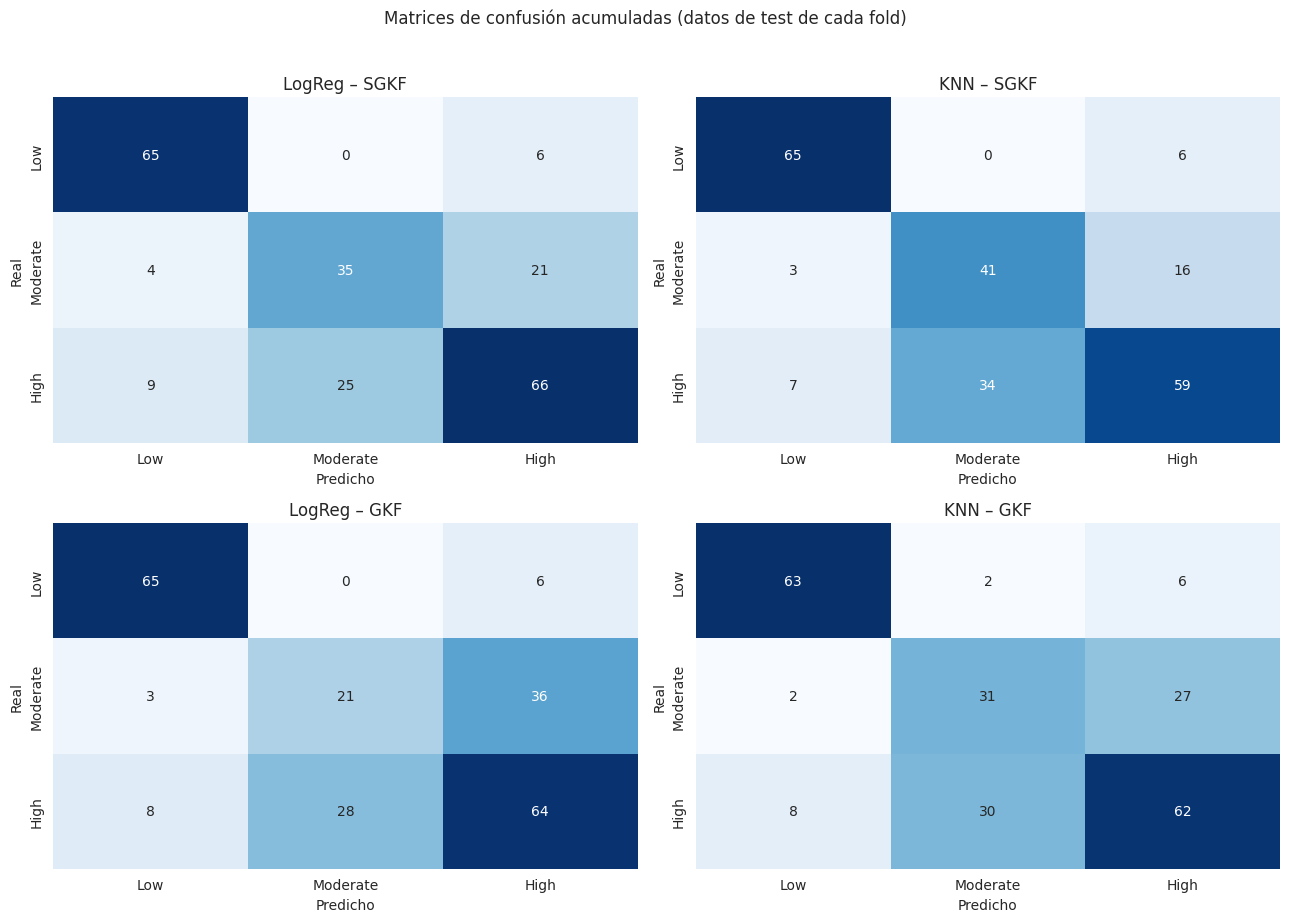


=== Reporte por clase – LogReg-SGKF ===
              precision    recall  f1-score   support

         Low       0.83      0.92      0.87        71
    Moderate       0.58      0.58      0.58        60
        High       0.71      0.66      0.68       100

    accuracy                           0.72       231
   macro avg       0.71      0.72      0.71       231
weighted avg       0.71      0.72      0.72       231


=== Reporte por clase – KNN-SGKF ===
              precision    recall  f1-score   support

         Low       0.87      0.92      0.89        71
    Moderate       0.55      0.68      0.61        60
        High       0.73      0.59      0.65       100

    accuracy                           0.71       231
   macro avg       0.71      0.73      0.72       231
weighted avg       0.72      0.71      0.71       231


=== Reporte por clase – LogReg-GKF ===
              precision    recall  f1-score   support

         Low       0.86      0.92      0.88        71
    Modera

In [13]:
# ---------------------------
# 8. MATRICES DE CONFUSIÓN ACUMULADAS
# ---------------------------
etiquetas = ['Low', 'Moderate', 'High']

def plot_cm_acumulada(y_true, y_pred, titulo, ax):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=etiquetas, yticklabels=etiquetas,
                ax=ax, cbar=False)
    ax.set_title(titulo)
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_cm_acumulada(y_true_lr_sg,  y_pred_lr_sg,  'LogReg – SGKF', axes[0, 0])
plot_cm_acumulada(y_true_knn_sg, y_pred_knn_sg, 'KNN – SGKF',    axes[0, 1])
plot_cm_acumulada(y_true_lr_gk,  y_pred_lr_gk,  'LogReg – GKF',  axes[1, 0])
plot_cm_acumulada(y_true_knn_gk, y_pred_knn_gk, 'KNN – GKF',     axes[1, 1])
plt.suptitle('Matrices de confusión acumuladas (datos de test de cada fold)',
             y=1.02)
plt.tight_layout()
plt.show()

# Reportes por clase
for nombre, yt, yp in [
    ('LogReg-SGKF', y_true_lr_sg,  y_pred_lr_sg),
    ('KNN-SGKF',    y_true_knn_sg, y_pred_knn_sg),
    ('LogReg-GKF',  y_true_lr_gk,  y_pred_lr_gk),
    ('KNN-GKF',     y_true_knn_gk, y_pred_knn_gk),
]:
    print(f"\n=== Reporte por clase – {nombre} ===")
    print(classification_report(yt, yp, labels=[0, 1, 2],
                                 target_names=etiquetas, zero_division=0))

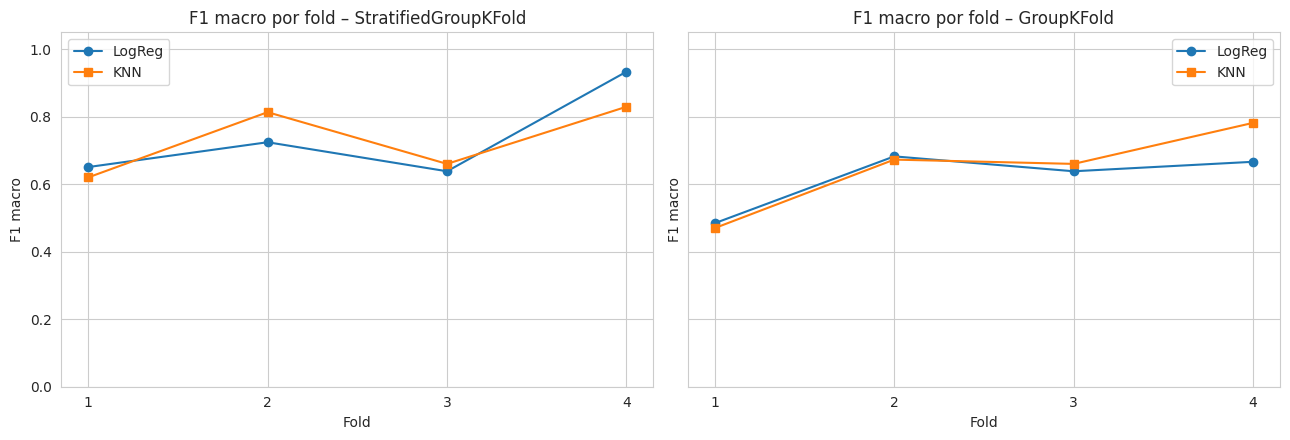

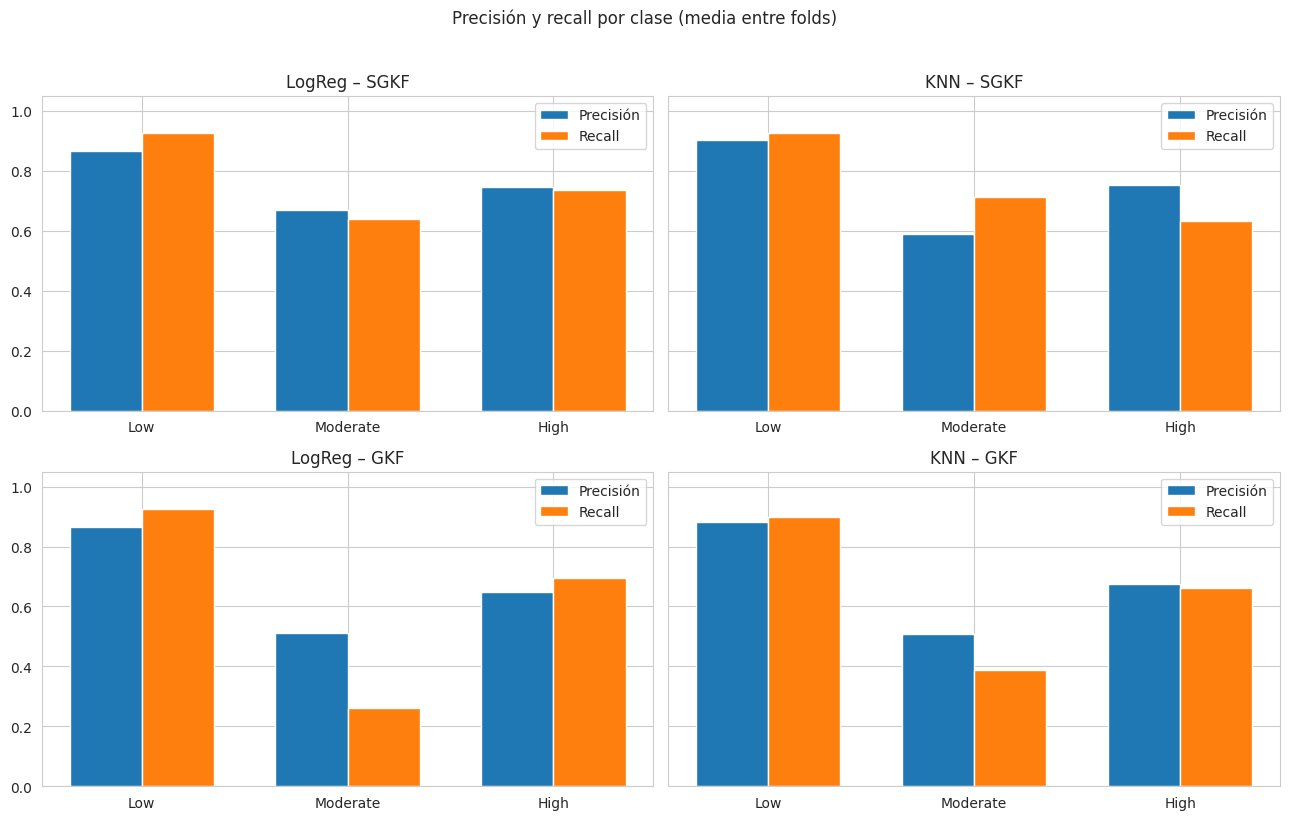

In [14]:
# ---------------------------
# 9. GRÁFICOS COMPARATIVOS DE MODELOS
# ---------------------------
# F1 macro por fold
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (nombre, r_lr, r_knn) in zip(
        axes,
        [('StratifiedGroupKFold', res_lr_sg, res_knn_sg),
         ('GroupKFold', res_lr_gk, res_knn_gk)]):
    xx = np.arange(len(r_lr)) + 1
    ax.plot(xx, r_lr['f1_macro'], marker='o', label='LogReg')
    ax.plot(xx, r_knn['f1_macro'], marker='s', label='KNN')
    ax.set_title(f'F1 macro por fold – {nombre}')
    ax.set_xlabel('Fold')
    ax.set_ylabel('F1 macro')
    ax.set_xticks(xx)
    ax.set_ylim(0, 1.05)
    ax.legend()
plt.tight_layout()
plt.show()

# Precisión y recall por clase
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
combinaciones = [
    ('LogReg – SGKF',  res_lr_sg,  axes[0, 0]),
    ('KNN – SGKF',     res_knn_sg, axes[0, 1]),
    ('LogReg – GKF',   res_lr_gk,  axes[1, 0]),
    ('KNN – GKF',      res_knn_gk, axes[1, 1]),
]
for titulo, res, ax in combinaciones:
    media_p = [res[f'prec_{i}'].mean() for i in range(3)]
    media_r = [res[f'rec_{i}'].mean() for i in range(3)]
    xx = np.arange(3); w = 0.35
    ax.bar(xx - w/2, media_p, w, label='Precisión')
    ax.bar(xx + w/2, media_r, w, label='Recall')
    ax.set_xticks(xx); ax.set_xticklabels(etiquetas)
    ax.set_ylim(0, 1.05)
    ax.set_title(titulo)
    ax.legend()
plt.suptitle('Precisión y recall por clase (media entre folds)', y=1.02)
plt.tight_layout()
plt.show()

# **Importancia de variables y comparación de escenarios**


5. IMPORTANCIA DE VARIABLES


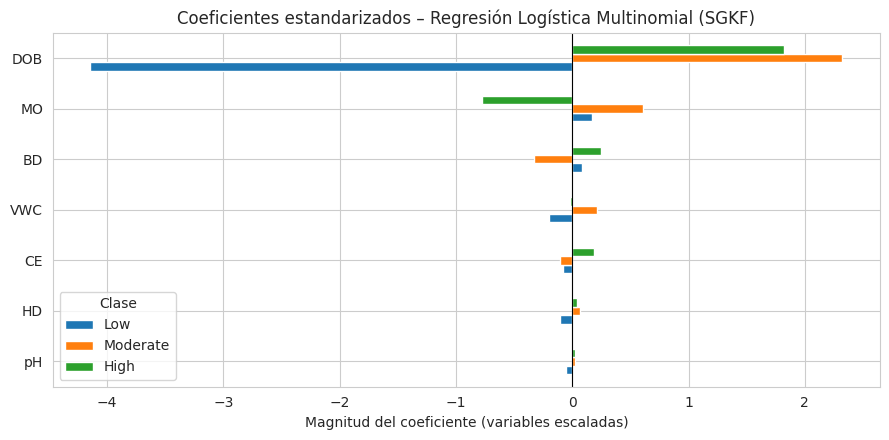


Coeficientes LogReg:
       Low  Moderate   High  abs_media
pH  -0.051     0.028  0.023      0.034
HD  -0.108     0.066  0.042      0.072
CE  -0.082    -0.103  0.185      0.123
VWC -0.198     0.215 -0.017      0.143
BD   0.082    -0.327  0.245      0.218
MO   0.169     0.610 -0.779      0.519
DOB -4.145     2.324  1.821      2.763


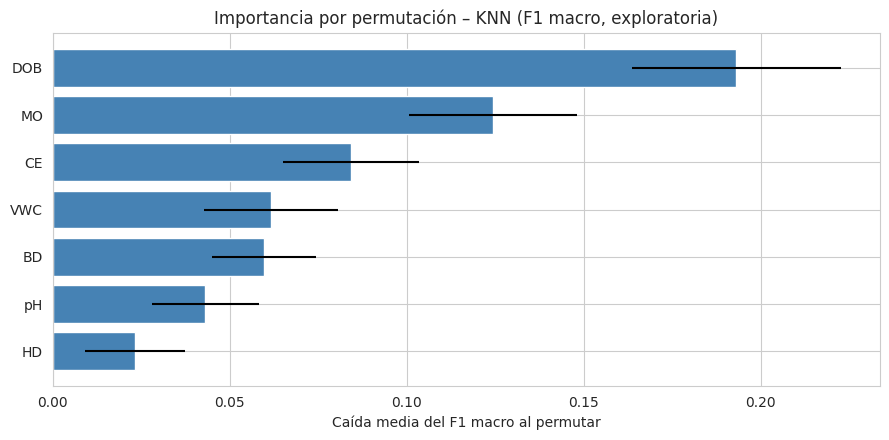


Importancia por permutación KNN:
  variable  importancia_media  importancia_sd
4       HD             0.0232          0.0142
0       pH             0.0430          0.0151
5       BD             0.0596          0.0147
6      VWC             0.0617          0.0190
1       CE             0.0842          0.0192
3       MO             0.1244          0.0238
2      DOB             0.1931          0.0294


In [15]:
# ---------------------------
# 10. IMPORTANCIA DE VARIABLES (modelo SGKF, que es el principal)
# ---------------------------
print("\n" + "=" * 70)
print("5. IMPORTANCIA DE VARIABLES")
print("=" * 70)

# 10.1 Coeficientes LogReg (modelo del último fold SGKF)
coefs = modelo_lr_sg.named_steps['clf'].coef_  # (n_clases, n_features)
clases = ['Low', 'Moderate', 'High']
df_coef = pd.DataFrame(coefs.T, index=features, columns=clases)
df_coef['abs_media'] = df_coef.abs().mean(axis=1)
df_coef = df_coef.sort_values('abs_media', ascending=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
df_coef[clases].plot(kind='barh', ax=ax)
ax.set_title('Coeficientes estandarizados – Regresión Logística Multinomial (SGKF)')
ax.set_xlabel('Magnitud del coeficiente (variables escaladas)')
ax.axvline(0, color='k', lw=.8)
ax.legend(title='Clase')
plt.tight_layout()
plt.show()
print("\nCoeficientes LogReg:")
print(df_coef.round(3))

# 10.2 Importancia por permutación KNN
# Nota: se calcula sobre el modelo full entrenado con todos los datos
# y evaluado sobre los mismos datos (exploratoria). El objetivo es
# CONSENSUAR con los coeficientes, no validar el subconjunto.
modelo_knn_full = construir_pipeline_knn(features).fit(X, y)
perm = permutation_importance(
    modelo_knn_full, X, y, n_repeats=30,
    random_state=RANDOM_STATE, scoring='f1_macro', n_jobs=-1)
df_perm = pd.DataFrame({
    'variable': features,
    'importancia_media': perm.importances_mean,
    'importancia_sd': perm.importances_std
}).sort_values('importancia_media', ascending=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(df_perm['variable'], df_perm['importancia_media'],
        xerr=df_perm['importancia_sd'], color='steelblue')
ax.set_title('Importancia por permutación – KNN (F1 macro, exploratoria)')
ax.set_xlabel('Caída media del F1 macro al permutar')
plt.tight_layout()
plt.show()
print("\nImportancia por permutación KNN:")
print(df_perm.round(4))

VARIABLES RELEVANTES: CONSENSO LogReg (coef) vs KNN (permutación)
Umbral de |coef| medio (mediana): 0.1431

Candidatas por coeficientes LogReg (4): ['BD', 'DOB', 'MO', 'VWC']
Candidatas por permutación KNN  (7): ['BD', 'CE', 'DOB', 'HD', 'MO', 'VWC', 'pH']

>>> Subconjunto reducido (consenso): ['BD', 'DOB', 'MO', 'VWC']
>>> Variables excluidas: ['pH', 'CE', 'HD']

Tabla integrada de relevancia:
variable  coef_abs_media_LogReg  coef_Low  coef_Moderate  coef_High  perm_media_KNN  perm_sd_KNN  candidata_coef  candidata_perm  en_subconjunto
     DOB                 2.7633   -4.1450         2.3236     1.8214          0.1931       0.0294            True            True            True
      MO                 0.5192    0.1688         0.6100    -0.7788          0.1244       0.0238            True            True            True
      BD                 0.2183    0.0824        -0.3275     0.2451          0.0596       0.0147            True            True            True
     VWC              

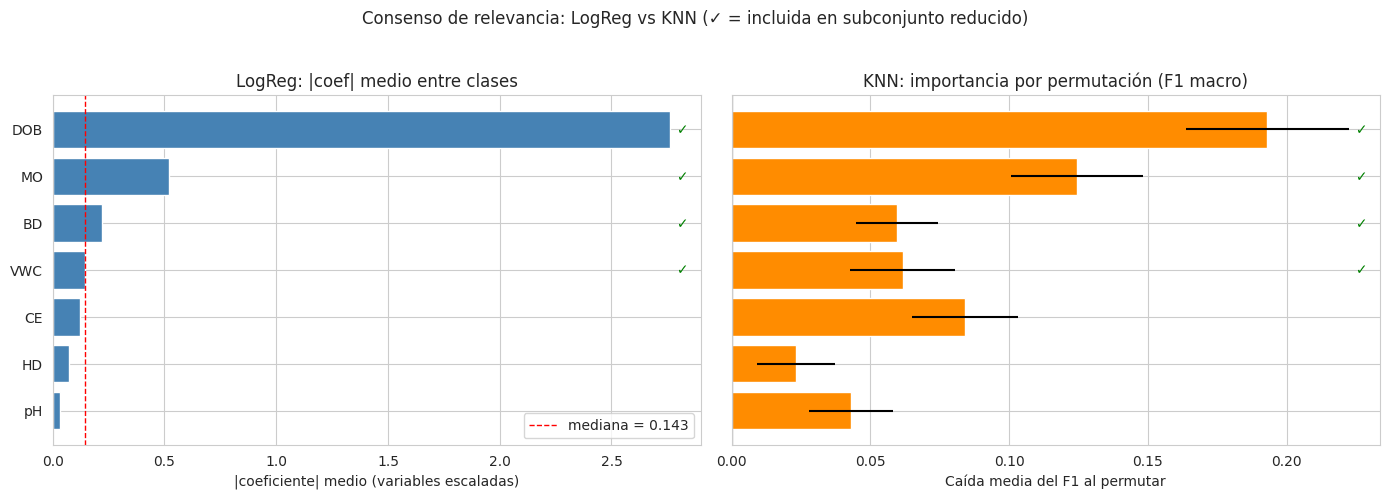

In [16]:
# ---------------------------------------------------
# 10.3. DEFINICIÓN DE VARIABLES RELEVANTES Y CONSENSO
# ---------------------------------------------------

# --- 10.3.1. Candidatas por coeficientes de LogReg ---
umbral_coef = df_coef['abs_media'].median()
candidatas_coef = sorted(
    df_coef[df_coef['abs_media'] >= umbral_coef].index)

# --- 10.3.2. Candidatas por permutación KNN ---
candidatas_perm = sorted(
    df_perm[df_perm['importancia_media'] > 0]['variable'])

# --- 10.3.3. Consenso (intersección) ---
seleccion = sorted(set(candidatas_coef) & set(candidatas_perm))
fallback_usado = False
if len(seleccion) < 2:
    seleccion = list(
        df_coef.sort_values('abs_media', ascending=False).head(3).index)
    fallback_usado = True

excluidas = [f for f in features if f not in seleccion]

# --- 10.3.4. Tabla integrada de relevancia ---
tabla_relevancia = pd.DataFrame({
    'variable': features,
    'coef_abs_media_LogReg': [
        df_coef.loc[f, 'abs_media'] if f in df_coef.index else np.nan
        for f in features],
    'coef_Low': [
        df_coef.loc[f, 'Low'] if f in df_coef.index else np.nan
        for f in features],
    'coef_Moderate': [
        df_coef.loc[f, 'Moderate'] if f in df_coef.index else np.nan
        for f in features],
    'coef_High': [
        df_coef.loc[f, 'High'] if f in df_coef.index else np.nan
        for f in features],
    'perm_media_KNN': [
        df_perm.loc[df_perm['variable'] == f, 'importancia_media'].values[0]
        if f in df_perm['variable'].values else np.nan
        for f in features],
    'perm_sd_KNN': [
        df_perm.loc[df_perm['variable'] == f, 'importancia_sd'].values[0]
        if f in df_perm['variable'].values else np.nan
        for f in features],
})
tabla_relevancia['candidata_coef'] = tabla_relevancia['variable'].isin(candidatas_coef)
tabla_relevancia['candidata_perm'] = tabla_relevancia['variable'].isin(candidatas_perm)
tabla_relevancia['en_subconjunto'] = tabla_relevancia['variable'].isin(seleccion)
tabla_relevancia = tabla_relevancia.sort_values(
    'coef_abs_media_LogReg', ascending=False).reset_index(drop=True)

print("=" * 70)
print("VARIABLES RELEVANTES: CONSENSO LogReg (coef) vs KNN (permutación)")
print("=" * 70)
print(f"Umbral de |coef| medio (mediana): {umbral_coef:.4f}")
print(f"\nCandidatas por coeficientes LogReg ({len(candidatas_coef)}): "
      f"{candidatas_coef}")
print(f"Candidatas por permutación KNN  ({len(candidatas_perm)}): "
      f"{candidatas_perm}")
print(f"\n>>> Subconjunto reducido (consenso): {seleccion}")
print(f">>> Variables excluidas: {excluidas}")
if fallback_usado:
    print("    (Se aplicó fallback: la intersección tenía <2 variables; "
          "se tomaron las 3 top por |coef| medio.)")

print("\nTabla integrada de relevancia:")
print(tabla_relevancia.round(4).to_string(index=False))

# --- 10.3.5. Gráfico integrado de relevancia ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
ord_vars = tabla_relevancia.sort_values('coef_abs_media_LogReg')['variable']

axes[0].barh(ord_vars,
             tabla_relevancia.set_index('variable')
             .loc[ord_vars, 'coef_abs_media_LogReg'].values,
             color='steelblue')
axes[0].set_title('LogReg: |coef| medio entre clases')
axes[0].set_xlabel('|coeficiente| medio (variables escaladas)')
axes[0].axvline(umbral_coef, color='red', ls='--', lw=1,
                label=f'mediana = {umbral_coef:.3f}')
axes[0].legend()

axes[1].barh(ord_vars,
             tabla_relevancia.set_index('variable')
             .loc[ord_vars, 'perm_media_KNN'].values,
             xerr=tabla_relevancia.set_index('variable')
             .loc[ord_vars, 'perm_sd_KNN'].values,
             color='darkorange')
axes[1].set_title('KNN: importancia por permutación (F1 macro)')
axes[1].set_xlabel('Caída media del F1 al permutar')
axes[1].axvline(0, color='k', lw=.8)

# Marcar las seleccionadas en ambos paneles
for ax in axes:
    for i, v in enumerate(ord_vars):
        if v in seleccion:
            ax.text(ax.get_xlim()[1] * 0.98, i, ' ✓',
                    va='center', ha='right', color='green',
                    fontweight='bold')

plt.suptitle('Consenso de relevancia: LogReg vs KNN '
             '(✓ = incluida en subconjunto reducido)', y=1.03)
plt.tight_layout()
plt.show()


6. COMPARACIÓN DE ESCENARIOS (con StratifiedGroupKFold)

--- Escenario A-completo (7 vars) ---

--- Escenario B-reducido (4 vars) ---

=== Comparación de escenarios ===
   Escenario  n_vars                    variables  F1_LR_media  F1_LR_sd  F1_KNN_media  F1_KNN_sd
A – completo       7 pH, CE, DOB, MO, HD, BD, VWC        0.737     0.136         0.731      0.106
B – reducido       4             BD, DOB, MO, VWC        0.729     0.116         0.701      0.096

Diferencia F1 macro (A - B):  LogReg=+0.008  KNN=+0.030
Interpretación: si |diferencia| < sd entre folds, la reducción es defendible como técnicamente equivalente.


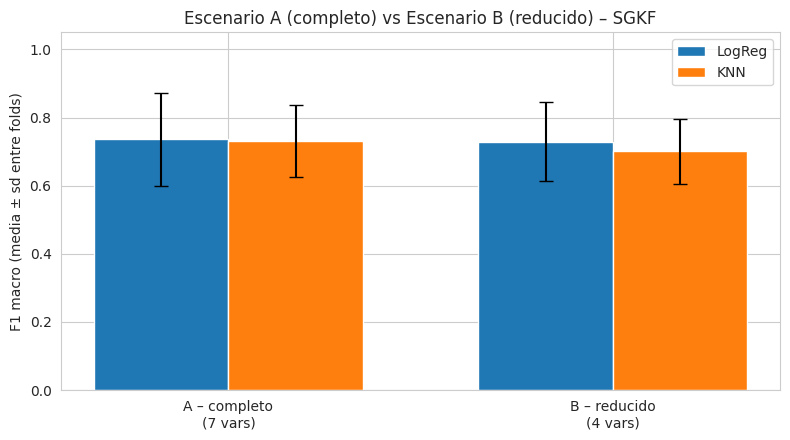

In [17]:
# ---------------------------------------------------------
# 11. COMPARACIÓN DE ESCENARIOS A (completo) vs B (reducido)
# ---------------------------------------------------------
print("\n" + "=" * 70)
print("6. COMPARACIÓN DE ESCENARIOS (con StratifiedGroupKFold)")
print("=" * 70)

def correr_escenario(features_sel, nombre_esc, folds):
    Xs = df[features_sel].copy()
    p_lr = construir_pipeline_logreg(features_sel)
    p_knn = construir_pipeline_knn(features_sel)
    print(f"\n--- Escenario {nombre_esc} ({len(features_sel)} vars) ---")
    _, _, r_lr, _ = evaluar_modelo_cv(
        f"LR-{nombre_esc}", p_lr, Xs, y, grupos, folds)
    _, _, r_knn, _ = evaluar_modelo_cv(
        f"KNN-{nombre_esc}", p_knn, Xs, y, grupos, folds,
        param_grid=param_grid_knn, needs_grid=True)
    return r_lr, r_knn

res_A_lr, res_A_knn = correr_escenario(features, "A-completo", folds_sgkf)
res_B_lr, res_B_knn = correr_escenario(seleccion, "B-reducido", folds_sgkf)

filas = []
for esc, feats, r_lr, r_knn in [
    ('A – completo', features,  res_A_lr, res_A_knn),
    ('B – reducido', seleccion, res_B_lr, res_B_knn),
]:
    filas.append({
        'Escenario': esc,
        'n_vars': len(feats),
        'variables': ', '.join(feats),
        'F1_LR_media':  r_lr['f1_macro'].mean(),
        'F1_LR_sd':     r_lr['f1_macro'].std(),
        'F1_KNN_media': r_knn['f1_macro'].mean(),
        'F1_KNN_sd':    r_knn['f1_macro'].std(),
    })
tabla_esc = pd.DataFrame(filas)
print("\n=== Comparación de escenarios ===")
print(tabla_esc.round(3).to_string(index=False))

# Diferencia A - B
dif_lr = (tabla_esc.loc[0, 'F1_LR_media'] - tabla_esc.loc[1, 'F1_LR_media'])
dif_knn = (tabla_esc.loc[0, 'F1_KNN_media'] - tabla_esc.loc[1, 'F1_KNN_media'])
print(f"\nDiferencia F1 macro (A - B):  LogReg={dif_lr:+.3f}  KNN={dif_knn:+.3f}")
print("Interpretación: si |diferencia| < sd entre folds, la reducción es "
      "defendible como técnicamente equivalente.")

# Gráfico comparativo de escenarios
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [f'A – completo\n({len(features)} vars)',
          f'B – reducido\n({len(seleccion)} vars)']
lr_means = [res_A_lr['f1_macro'].mean(), res_B_lr['f1_macro'].mean()]
lr_sds   = [res_A_lr['f1_macro'].std(),  res_B_lr['f1_macro'].std()]
knn_means = [res_A_knn['f1_macro'].mean(), res_B_knn['f1_macro'].mean()]
knn_sds   = [res_A_knn['f1_macro'].std(),  res_B_knn['f1_macro'].std()]
xx = np.arange(2); w = 0.35
ax.bar(xx - w/2, lr_means, w, yerr=lr_sds, capsize=5, label='LogReg')
ax.bar(xx + w/2, knn_means, w, yerr=knn_sds, capsize=5, label='KNN')
ax.set_xticks(xx); ax.set_xticklabels(labels)
ax.set_ylabel('F1 macro (media ± sd entre folds)')
ax.set_ylim(0, 1.05)
ax.set_title('Escenario A (completo) vs Escenario B (reducido) – SGKF')
ax.legend()
plt.tight_layout()
plt.show()

In [18]:
# ---------------------------
# 12. RESUMEN FINAL IMPRIMIBLE
# ---------------------------
print("\n" + "=" * 70)
print("7. RESUMEN FINAL")
print("=" * 70)
print(f"Variables totales      : {len(features)}")
print(f"Variables seleccionadas: {len(seleccion)} -> {seleccion}")
print(f"Variables excluidas    : {[f for f in features if f not in seleccion]}")
print("\nF1 macro (media entre folds, StratifiedGroupKFold):")
print(f"  Conjunto completo  -> LogReg: "
      f"{res_A_lr['f1_macro'].mean():.3f} ± {res_A_lr['f1_macro'].std():.3f}"
      f"  |  KNN: {res_A_knn['f1_macro'].mean():.3f} ± "
      f"{res_A_knn['f1_macro'].std():.3f}")
print(f"  Subconjunto reducido -> LogReg: "
      f"{res_B_lr['f1_macro'].mean():.3f} ± {res_B_lr['f1_macro'].std():.3f}"
      f"  |  KNN: {res_B_knn['f1_macro'].mean():.3f} ± "
      f"{res_B_knn['f1_macro'].std():.3f}")
print("\nRecordatorio metodológico: solo 7 turberas -> alta varianza en la "
      "estimación de generalización. Los resultados son indicativos.")
print("\nFin del análisis.")


7. RESUMEN FINAL
Variables totales      : 7
Variables seleccionadas: 4 -> ['BD', 'DOB', 'MO', 'VWC']
Variables excluidas    : ['pH', 'CE', 'HD']

F1 macro (media entre folds, StratifiedGroupKFold):
  Conjunto completo  -> LogReg: 0.737 ± 0.136  |  KNN: 0.731 ± 0.106
  Subconjunto reducido -> LogReg: 0.729 ± 0.116  |  KNN: 0.701 ± 0.096

Recordatorio metodológico: solo 7 turberas -> alta varianza en la estimación de generalización. Los resultados son indicativos.

Fin del análisis.
